# 3.6 — Marginación por colonia y carga de IRA

**Aspecto de la rúbrica:** relación espacial entre variables + la segunda
pregunta del proyecto ("¿las zonas más marginadas de Hermosillo son las más
afectadas por las enfermedades respiratorias?").

Hasta aquí la marginación solo existía como **un número para todo el
municipio** — con eso no se puede comparar zonas dentro de la ciudad. Esta
libreta baja el análisis al nivel **colonia**, usando tres piezas que ya
existen:

- La **cartografía de colonias** de CONAPO 2020, que trae en un solo archivo
  el polígono, el índice de marginación y la población de cada colonia.
- Las **103 unidades de salud (CLUES)** que reportaron IRA, con latitud y
  longitud del catálogo DGIS.
- Los **casos semanales de IRA por unidad**, del archivo SUIVE de Hermosillo.


## Resumen

- **El análisis intra-urbano sí se puede hacer:** las 103 unidades CLUES
  tienen coordenadas tras corregir a mano las 17 con registro erróneo del
  catálogo DGIS (consultorios de farmacia; ver
  `references/salud/nota_calidad_clues_coordenadas.md`) — **91** caen dentro
  de una colonia de Hermosillo → 63 colonias concentran el 94 % de los casos
  de IRA (de 657 colonias); 12 unidades quedan fuera: 10 en los bordes del
  municipio y 2 en los poblados de Miguel Alemán y Bahía de Kino.
- **La red de unidades no está sesgada:** la marginación media de las colonias
  con unidad que reporta (0.976) es casi idéntica a la de las que no tienen
  (0.975) — las clínicas no están concentradas ni en las zonas más ni en las
  menos marginadas.
- **La "tasa" por colonia está dominada por dónde están los hospitales:** la
  colonia Modelo (sede del HIES) suma ~780 mil casos y una tasa inflada —
  atiende a toda la ciudad, no solo a sus vecinos. Es el ejemplo perfecto del
  sesgo de usar la ubicación de la unidad en vez de la residencia del
  paciente.
- **No hay asociación marginación–carga de IRA:** Spearman ρ = 0.19
  (p = 0.14, n = 63 colonias).
- **La temporada golpea igual a todos:** la amplitud invierno/verano de la
  tasa es x3.0 en colonias "Muy bajo" y x2.9 en "Bajo" — el efecto estacional
  es el mismo. Y ya sin la época, ningún grupo reacciona más a las anomalías
  de temperatura o sequía (correlaciones ≈ 0 en ambos).
- **El hueco más importante:** las 12 colonias de grado Alto/Muy alto (las más
  marginadas de la ciudad) **no tienen ninguna unidad que reporte** — no hay
  observatorio ahí. La pregunta de vulnerabilidad por residencia queda
  abierta y requeriría el domicilio del paciente, no el de la clínica.

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/interim/marginacion/colonias_marginacion_hermosillo.gpkg` | Las 657 colonias de Hermosillo con polígono, índice de marginación y población (CONAPO 2020; la descarga y el recorte se hacen en `01_ingesta/1.3`) |
| `data/external/clues/clues_hermosillo_ira.csv` | Las 103 unidades que reportaron IRA en Hermosillo, con lat/lon del catálogo DGIS (notebook `1.5` / `download-clues-data`) |
| `data/raw/salud/enf_resp_sonora_2010_2020.csv` | Casos semanales de IRA por unidad (`clues`), 2010–2020; se filtra a Hermosillo (`clave_municipio == 30`) |
| `data/processed/panel_eda_semanal.parquet` | Exposiciones semanales del paso 7 de `3.0` (solo para la sección 6) |

## Salidas

- Figuras en `reports/figures/`: `mapa_marginacion_colonias.png`, `mapa_tasa_ira_colonias.png`, `marginacion_vs_tasa_ira.png`, `series_ira_por_marginacion.png`, `anomalias_por_marginacion.png`.

## Checklist

- [x] Leer la cartografía de colonias de Hermosillo (descargada y filtrada en `1.3`)
- [x] Georreferenciar las unidades CLUES (`stations_to_gdf`) y reportar cobertura de coordenadas
- [x] Spatial join unidad → colonia (`assign_stations_to_areas`, predicado `within`)
- [x] Sumar casos por colonia y calcular tasa por 100,000 hab (`POBTOT`)
- [x] Mapas coropléticos: marginación + unidades, y carga de IRA
- [x] Correlación marginación vs. tasa (Spearman, n pequeño → rangos)
- [x] Series semanales por grupo de marginación + reacción a anomalías de clima/aire
- [x] Resumen y conclusiones; [ ] consulta con el equipo

## Advertencia — leer antes de interpretar

- **La tasa es carga de atención, no incidencia de residentes.** La clave
  CLUES marca *dónde está la clínica*, no *dónde vive el paciente*. Una
  colonia con hospital grande puede concentrar casos de toda la ciudad. Por
  eso el resultado correcto de leer es: "las unidades en colonias así
  atendieron tantos casos por habitante local", no "la gente de esta colonia
  enferma más".
- **Las colonias sin unidad no tienen observatorio** (gris en el mapa). El
  análisis solo cubre la parte de la ciudad donde hay unidad que reporte.
- **Las 12 colonias más marginadas (grado Alto/Muy alto) no tienen ninguna
  unidad que reporte** — la comparación de la sección 6 solo va de "Muy bajo"
  a "Bajo". La pregunta de vulnerabilidad por residencia sigue abierta: haría
  falta la colonia de residencia del paciente, no la de la unidad.
- **Clima y sequía no varían por colonia** (un solo valor municipal por
  semana): la comparación por grupo mide si la *respuesta temporal* difiere,
  no diferencias de exposición.
- **Es una asociación ecológica**: aunque la correlación saliera alta, no
  dice que la marginación *cause* los casos.


## Configuración e imports

In [1]:
from pathlib import Path  # Path: manejar rutas de carpetas y archivos
import sys  # sys: cambiar dónde busca módulos Python

# Este notebook vive en notebooks/03_eda/: subimos dos carpetas hasta la raíz del proyecto
ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import geopandas as gpd  # mapas: leer shapefiles y hacer spatial joins
import matplotlib.pyplot as plt  # gráficas
import pandas as pd  # tablas
from scipy import stats  # correlación de Spearman

from sonora_health_climate_eda.config import (
    EXTERNAL_DATA_DIR,
    FIGURES_DIR,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    RAW_DATA_DIR,
)
from sonora_health_climate_eda.spatial import assign_stations_to_areas, stations_to_gdf

## 1. Capa de colonias

Se lee la capa de colonias de Hermosillo que deja el notebook de ingesta
`01_ingesta/1.3-indice_-marginacion.ipynb` (sección "Colonias 2020"): el SHP
nacional de CONAPO ya recortado al municipio (`CVE_MUN == '26030'`).

In [2]:
GPKG = INTERIM_DATA_DIR / "marginacion" / "colonias_marginacion_hermosillo.gpkg"

if not GPKG.exists():
    raise FileNotFoundError(
        f"No existe {GPKG}. Corre primero la sección 'Colonias 2020' del notebook "
        "01_ingesta/1.3-indice_-marginacion.ipynb."
    )
colonias = gpd.read_file(GPKG)

print(f"{len(colonias)} colonias de Hermosillo, CRS {colonias.crs}")
print("Colonias por grado de marginación:")
print(colonias["GM_2020"].value_counts().to_string())
print(f"Población total cubierta: {colonias['POBTOT'].sum():,.0f} hab")

657 colonias de Hermosillo, CRS EPSG:4326
Colonias por grado de marginación:
GM_2020
Muy bajo    452
Bajo        159
Medio        34
Muy alto      8
Alto          4
Población total cubierta: 834,135 hab


## 2. Mapa de marginación con las unidades de salud

Primero el mapa base: cada colonia pintada por su **grado de marginación**
(`GM_2020`, las cinco categorías oficiales de CONAPO, ordenadas de *Muy bajo*
en amarillo a *Muy alto* en morado), con las unidades de salud encima como
puntos. Se usa el grado y no el índice continuo porque casi toda la ciudad
concentra el mismo índice (IMN ≈ 0.97) y el gradiente se vería de un solo
color. Las 17 CLUES con coordenadas erróneas o ausentes en el catálogo se
reposicionan con la tabla de correcciones
(`data/external/clues/clues_17_geocodificacion.csv`): 15 urbanas van a su
colonia/ubicación real y 2 rurales (poblados Miguel Alemán y Bahía de Kino)
quedan fuera de la vista a propósito.

> **Nota:** ese CSV de correcciones es un **complemento manual** y no se
> versiona con el repo (`data/` está en `.gitignore`). Se construyó a mano
> cruzando el domicilio declarado contra las colonias de CONAPO y búsquedas
> en mapa — el procedimiento está en
> `references/salud/nota_calidad_clues_coordenadas.md`. Si el archivo no
> existe, la libreta corre sin las correcciones (menos cobertura) y avisa.

Unidades CLUES que reportaron IRA en Hermosillo: 103
  de ellas, 103 tienen coordenadas (17 corregidas a mano)


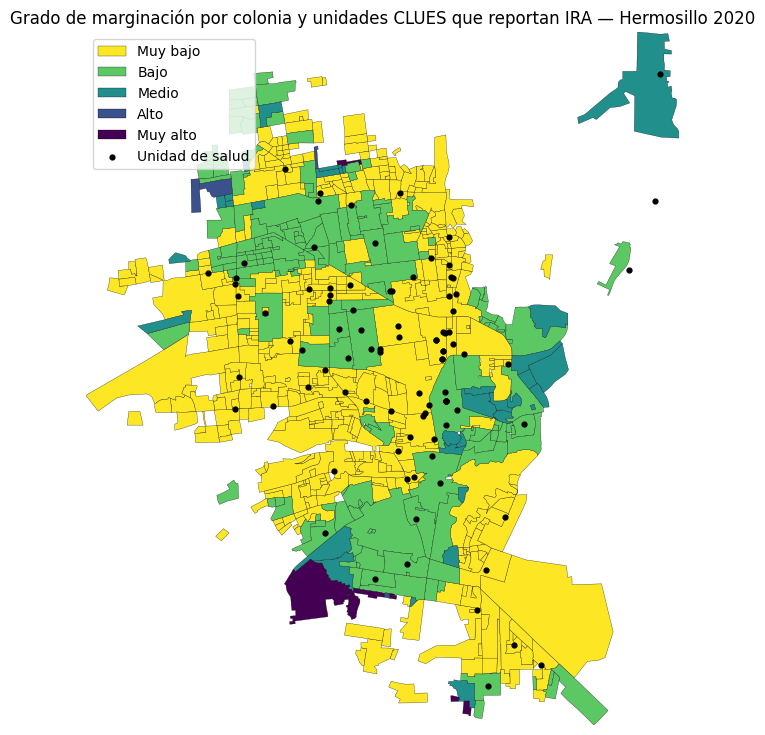

In [3]:
# Catálogo CLUES → puntos. Algunas unidades no traen lat/lon válida.
clues = pd.read_csv(EXTERNAL_DATA_DIR / "clues" / "clues_hermosillo_ira.csv", dtype=str)
clues["lat"] = pd.to_numeric(clues["LATITUD"], errors="coerce")
clues["lon"] = pd.to_numeric(clues["LONGITUD"], errors="coerce")

# Corrección manual de las 17 unidades con coordenadas erróneas (en CDMX) o
# ausentes en el catálogo — ver references/salud/nota_calidad_clues_coordenadas.md.
# IMPORTANTE: este archivo es un complemento manual y NO se versiona con el
# repo (data/ está en .gitignore). Sin él la libreta corre igual, pero sin
# las correcciones (menos cobertura: 76 unidades dentro de colonias en vez
# de 91). La forma de regenerarlo está documentada en la nota de calidad.
CORRECCIONES_CSV = EXTERNAL_DATA_DIR / "clues" / "clues_17_geocodificacion.csv"
n_corregidas = 0
if CORRECCIONES_CSV.exists():
    correcciones = pd.read_csv(CORRECCIONES_CSV)
    corr_map = correcciones.set_index("CLUES")[["LAT", "LON"]].astype(float)
    tiene_corr = clues["CLUES"].isin(corr_map.index)
    clues.loc[tiene_corr, "lat"] = clues.loc[tiene_corr, "CLUES"].map(corr_map["LAT"])
    clues.loc[tiene_corr, "lon"] = clues.loc[tiene_corr, "CLUES"].map(corr_map["LON"])
    n_corregidas = int(tiene_corr.sum())
else:
    print(f"AVISO: no se encontró {CORRECCIONES_CSV.name}; la libreta corre "
          "sin las 17 correcciones manuales (menos cobertura). "
          "Cómo generarlo: references/salud/nota_calidad_clues_coordenadas.md")

clues_ok = clues.dropna(subset=["lat", "lon"]).query("lat != 0 and lon != 0")
print(f"Unidades CLUES que reportaron IRA en Hermosillo: {len(clues)}")
print(f"  de ellas, {len(clues_ok)} tienen coordenadas ({n_corregidas} corregidas a mano)")

unidades = stations_to_gdf(clues_ok, lat_col="lat", lon_col="lon")

# Se pinta por GRADO de marginación (5 categorías ordenadas) y no por el
# índice continuo: como casi toda la ciudad tiene IMN ≈ 0.97, el gradiente
# se comprimía y las colonias se veían del mismo color.
ORDEN_GM = ["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]
colonias["GM_2020_cat"] = pd.Categorical(
    colonias["GM_2020"], categories=ORDEN_GM, ordered=True
)

fig, ax = plt.subplots(figsize=(10, 9))
colonias.plot(
    column="GM_2020_cat", categorical=True, cmap="viridis_r",
    legend=True, ax=ax, linewidth=0.2,edgecolor="black"
)
unidades.plot(ax=ax, color="black", markersize=12, label="Unidad de salud")
ax.legend()
# El mapa se encuadra en Hermosillo: las 2 unidades de los poblados
# (Miguel Alemán y Bahía de Kino) quedan fuera de la vista, a propósito.
xmin, ymin, xmax, ymax = colonias.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("Grado de marginación por colonia y unidades CLUES que reportan IRA — Hermosillo 2020")
ax.set_axis_off()
fig.savefig(FIGURES_DIR / "mapa_marginacion_colonias.png", dpi=150, bbox_inches="tight")
plt.show()

> **Cómo leer este mapa:** cada color es el grado oficial de marginación de
> la colonia (amarillo = Muy bajo → morado = Muy alto) y los puntos negros
> son unidades que reportan IRA. Lo primero que se nota: casi toda la ciudad
> es amarilla o verde, y las unidades están repartidas sin concentrarse en
> ningún grado en particular.


## 3. ¿En qué colonia está cada unidad?

El *spatial join* (`within`) le pone a cada punto de unidad el `CVE_COL`, el
nombre y el índice de marginación de la colonia que lo contiene. Se reporta la
cobertura: unidades que cayeron en una colonia y colonias con al menos una
unidad que reporte.


In [4]:
unidades_col = assign_stations_to_areas(
    colonias[["CVE_COL", "COLONIA", "IMN_2020", "GM_2020", "geometry"]],
    unidades,
)
con_match = unidades_col["CVE_COL"].notna()

print(f"Unidades que cayeron dentro de una colonia de Hermosillo: {con_match.sum()} de {len(unidades_col)}")
print(f"  (las otras {len(unidades_col) - con_match.sum()} están fuera del área urbana (10 en los bordes del municipio y 2 en los poblados))")
print(f"Colonias con al menos una unidad que reporta: {unidades_col['CVE_COL'].nunique()} de {len(colonias)}")

# ¿Las unidades están en colonias más o menos marginadas que el promedio?
imn_con = colonias.loc[colonias["CVE_COL"].isin(unidades_col["CVE_COL"]), "IMN_2020"].mean()
imn_sin = colonias.loc[~colonias["CVE_COL"].isin(unidades_col["CVE_COL"]), "IMN_2020"].mean()
print(f"\nMarginación media de colonias CON unidad:    {imn_con:.3f}")
print(f"Marginación media de colonias SIN unidad:    {imn_sin:.3f}")

2026-11-24 16:19:15.633 | INFO     | sonora_health_climate_eda.spatial:assign_stations_to_areas:110 - Spatial join: 103 estaciones → 63 áreas.
Unidades que cayeron dentro de una colonia de Hermosillo: 91 de 103
  (las otras 12 están fuera del área urbana (10 en los bordes del municipio y 2 en los poblados))
Colonias con al menos una unidad que reporta: 63 de 657

Marginación media de colonias CON unidad:    0.976
Marginación media de colonias SIN unidad:    0.975


## 4. Casos de IRA por colonia y tasa por 100 mil

Los casos semanales se suman por unidad (`clues`) en todo el período
2010–2020, se agregan a la colonia de cada unidad y se dividen entre su
población → **casos acumulados por 100,000 habitantes**. Las colonias sin
unidad que reporte quedan en gris: no es que no haya enfermos ahí, es que
**no hay observatorio**.


Casos de IRA reportados en Hermosillo, 2010-2020: 2,206,617
  de unidades ubicadas dentro de una colonia: 2,075,723 (94%)
  el resto (130,894) es de unidades fuera del área urbana cubierta por colonias (incl. los poblados)


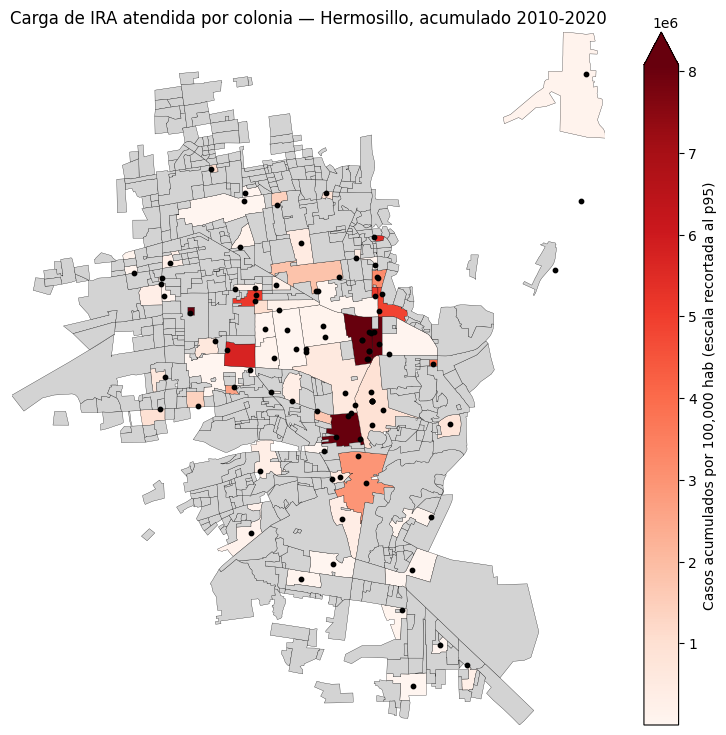

In [5]:
# Casos 2010-2020 por unidad: el CSV de Sonora filtrado a Hermosillo (clave_municipio 30)
ira = pd.read_csv(
    RAW_DATA_DIR / "salud" / "enf_resp_sonora_2010_2020.csv",
    usecols=["clave_municipio", "anio", "semana", "clues", "casos"],
).query("clave_municipio == 30")
casos_unidad = ira.groupby("clues")["casos"].sum().rename("casos_ira")
total_ira = int(casos_unidad.sum())

# Agrega los casos a la colonia de cada unidad y arma la tasa
unidades_col = unidades_col.merge(casos_unidad, left_on="CLUES", right_index=True, how="left")
colonias["casos_ira"] = (
    colonias["CVE_COL"].map(unidades_col.groupby("CVE_COL")["casos_ira"].sum())
)
colonias["tasa_ira_100k"] = colonias["casos_ira"] / colonias["POBTOT"] * 100_000

asignados = int(unidades_col.loc[con_match, "casos_ira"].sum())
print(f"Casos de IRA reportados en Hermosillo, 2010-2020: {total_ira:,}")
print(f"  de unidades ubicadas dentro de una colonia: {asignados:,} ({asignados / total_ira:.0%})")
print(f"  el resto ({total_ira - asignados:,}) es de unidades fuera del área urbana cubierta por colonias (incl. los poblados)")

# El mapa recorta la escala en el percentil 95: sin eso, la colonia-sede del
# HIES (que atiende a toda la ciudad) aplana todos los demás colores.
fig, ax = plt.subplots(figsize=(10, 9))
colonias.plot(
    column="tasa_ira_100k", cmap="Reds", legend=True, ax=ax, linewidth=0.2,
    vmax=colonias["tasa_ira_100k"].quantile(0.95),
    missing_kwds={"color": "lightgrey", "label": "Sin unidad que reporte"},
    legend_kwds={"label": "Casos acumulados por 100,000 hab (escala recortada al p95)"},
    edgecolor="black"
)
unidades.plot(ax=ax, color="black", markersize=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("Carga de IRA atendida por colonia — Hermosillo, acumulado 2010-2020")
ax.set_axis_off()
fig.savefig(FIGURES_DIR / "mapa_tasa_ira_colonias.png", dpi=150, bbox_inches="tight")
plt.show()

> **Cómo leer este mapa:** rojo más fuerte = más casos de IRA atendidos por
> cada 100 mil habitantes de la colonia (acumulado 2010–2020). **Gris = sin
> unidad que reporte**: no es cero casos, es *no hay observatorio*. Ojo: la
> tasa refleja dónde está la clínica — las colonias con hospital se ven muy
> rojas aunque atiendan a pacientes de toda la ciudad.


## 5. ¿Las colonias más marginadas concentran más carga de IRA?

Cada punto es una colonia **con unidad que reporte**: su marginación (eje x)
contra su tasa de casos (eje y). La correlación de **Spearman** resume si las
más marginadas tienden a tener tasas más altas.


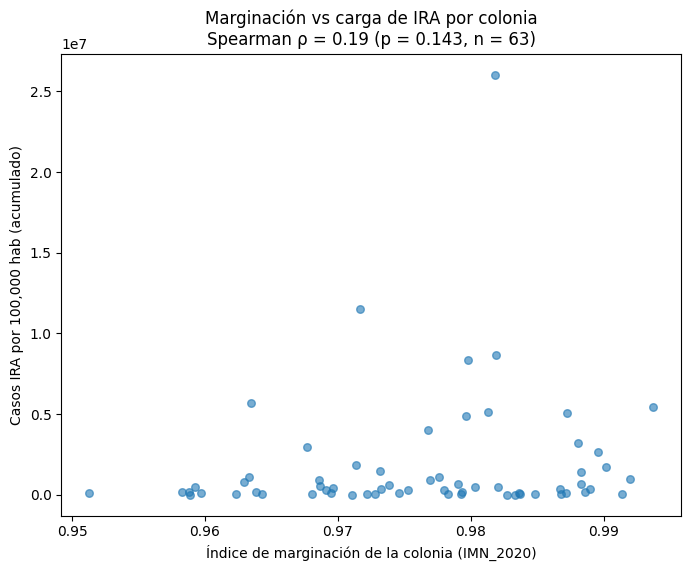

Tasa mediana de IRA por grado de marginación:
GM_2020
Muy bajo    469138.0
Bajo        243414.0
Medio        98195.0


In [6]:
con_unidad = colonias.dropna(subset=["tasa_ira_100k", "IMN_2020"])
rho, p = stats.spearmanr(con_unidad["IMN_2020"], con_unidad["tasa_ira_100k"])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(con_unidad["IMN_2020"], con_unidad["tasa_ira_100k"], alpha=0.6, s=30)
ax.set_xlabel("Índice de marginación de la colonia (IMN_2020)")
ax.set_ylabel("Casos IRA por 100,000 hab (acumulado)")
ax.set_title(f"Marginación vs carga de IRA por colonia\nSpearman ρ = {rho:.2f} (p = {p:.3f}, n = {len(con_unidad)})")
fig.savefig(FIGURES_DIR / "marginacion_vs_tasa_ira.png", dpi=150, bbox_inches="tight")
plt.show()

# Vista rápida por grado de marginación
por_grado = (
    con_unidad.groupby("GM_2020")["tasa_ira_100k"].median()
    .reindex(["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]).dropna()
)
print("Tasa mediana de IRA por grado de marginación:")
print(por_grado.round(0).to_string())


> **Cómo leer esta gráfica:** cada punto es **una colonia** que tiene unidad
> que reporte. Si las más marginadas concentraran más carga de IRA, la nube
> **subiría hacia la derecha**. No se inclina (ρ = 0.19, p = 0.14): con estos
> datos no hay asociación — y el punto que sobresale arriba es la
> colonia-hospital que atiende a toda la ciudad.

## 6. ¿Reaccionan distinto a la temporada las colonias más y menos marginadas?

El clima y la sequía **no se pueden cruzar por colonia**: hay un solo valor por
semana para todo Hermosillo (una estación ERNO, un municipio). Lo que sí se
puede preguntar es si **la serie de casos por grupo de marginación responde
distinto a la misma temporada y a las mismas anomalías térmicas**.

**Límite importante:** solo hay unidades que reportan en colonias de grado
**"Muy bajo"** (53 unidades) y **"Bajo"** (22) — más 1 unidad suelta en
"Medio". Las 12 colonias de grado **Alto/Muy alto no tienen unidad que
reporte**: ahí no hay observatorio, así que la comparación solo puede hacerse
entre "Muy bajo" y "Bajo".

- **Serie semanal por grupo:** casos por semana ÷ población de las colonias
  del grupo → tasa semanal por 100,000 hab. Así se comparan cargas comparables.
- **Amplitud estacional:** promedio enero-febrero ÷ promedio julio-agosto
  (igual que en 3.3).
- **Reacción a anomalías:** cada tasa menos su promedio de mes (sin la
  época), correlacionada con las anomalías de temperatura, sequía y aire del
  panel semanal.


Amplitud invierno/verano de la tasa semanal por grupo:
  Muy bajo : invierno 5055 vs verano 1703 → x3.0
  Bajo     : invierno 1832 vs verano 622 → x2.9


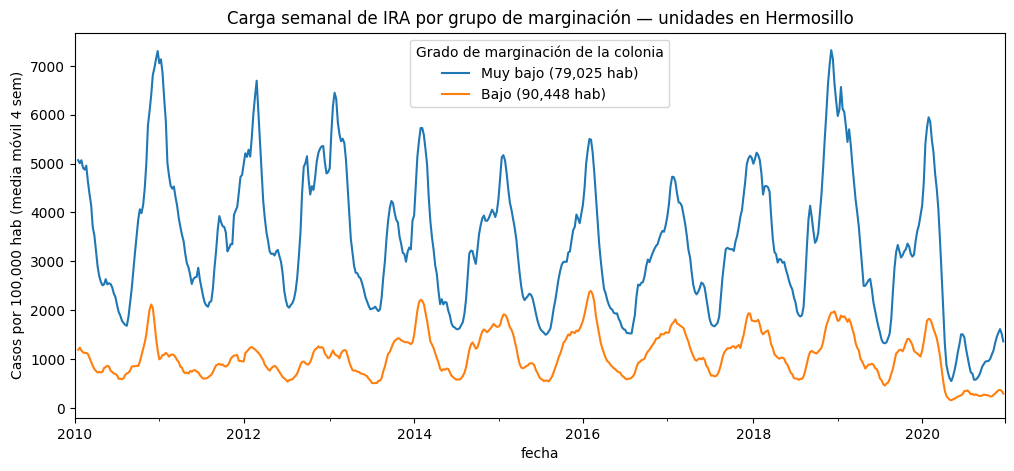

In [7]:
# Serie semanal de casos por grupo de marginación ("Muy bajo" vs "Bajo").
# Semana epidemiológica SINAVE: semanas de domingo a sábado y la SE1 es la que
# contiene el 4 de enero — la misma convención del panel semanal (panel.py).
def _se_start(anio, semana):
    jan4 = pd.Timestamp(anio, 1, 4)
    return jan4 - pd.Timedelta(days=(jan4.weekday() + 1) % 7) + pd.Timedelta(weeks=semana - 1)

GRUPOS = ["Muy bajo", "Bajo"]  # únicos con suficientes unidades que reportan
unidades_col["grupo_margin"] = unidades_col["GM_2020"].where(
    unidades_col["GM_2020"].isin(GRUPOS)
)
pob_grupo = (
    colonias.loc[colonias["CVE_COL"].isin(unidades_col["CVE_COL"])]
    .groupby("GM_2020")["POBTOT"].sum()
)

semanal = (
    ira.merge(unidades_col[["CLUES", "grupo_margin"]],
              left_on="clues", right_on="CLUES")
    .dropna(subset=["grupo_margin"])
    .groupby(["grupo_margin", "anio", "semana"])["casos"].sum()
    .reset_index()
)
semanal["tasa_100k"] = semanal.apply(
    lambda r: r["casos"] / pob_grupo[r["grupo_margin"]] * 100_000, axis=1
)
semanal["fecha"] = semanal.apply(
    lambda r: _se_start(int(r["anio"]), int(r["semana"])), axis=1
)

# Amplitud estacional: enero-febrero ÷ julio-agosto (2015-2019, sin pandemia)
s15 = semanal[semanal["anio"].between(2015, 2019)]
inv = s15[s15["semana"].between(1, 8)].groupby("grupo_margin")["tasa_100k"].mean()
ver = s15[s15["semana"].between(27, 34)].groupby("grupo_margin")["tasa_100k"].mean()
print("Amplitud invierno/verano de la tasa semanal por grupo:")
for g in GRUPOS:
    print(f"  {g:9s}: invierno {inv[g]:.0f} vs verano {ver[g]:.0f} → x{inv[g] / ver[g]:.1f}")

# Las dos series (suavizadas a 4 semanas para que se lean)
fig, ax = plt.subplots(figsize=(12, 5))
for g in GRUPOS:
    serie = semanal.set_index("fecha").loc[lambda d: d["grupo_margin"] == g, "tasa_100k"]
    serie.rolling(4, center=True).mean().plot(ax=ax, label=f"{g} ({pob_grupo[g]:,.0f} hab)")
ax.set_ylabel("Casos por 100,000 hab (media móvil 4 sem)")
ax.set_title("Carga semanal de IRA por grupo de marginación — unidades en Hermosillo")
ax.legend(title="Grado de marginación de la colonia")
fig.savefig(FIGURES_DIR / "series_ira_por_marginacion.png", dpi=150, bbox_inches="tight")
plt.show()

> **Cómo leer esta gráfica:** es la tasa semanal de casos por cada 100 mil
> habitantes de las colonias del grupo (media móvil de 4 semanas, para que se
> lea la forma y no el ruido). Las dos líneas suben y bajan **juntas** y con
> casi la misma amplitud: la temporada pega igual en colonias "Muy bajo" que
> en "Bajo".


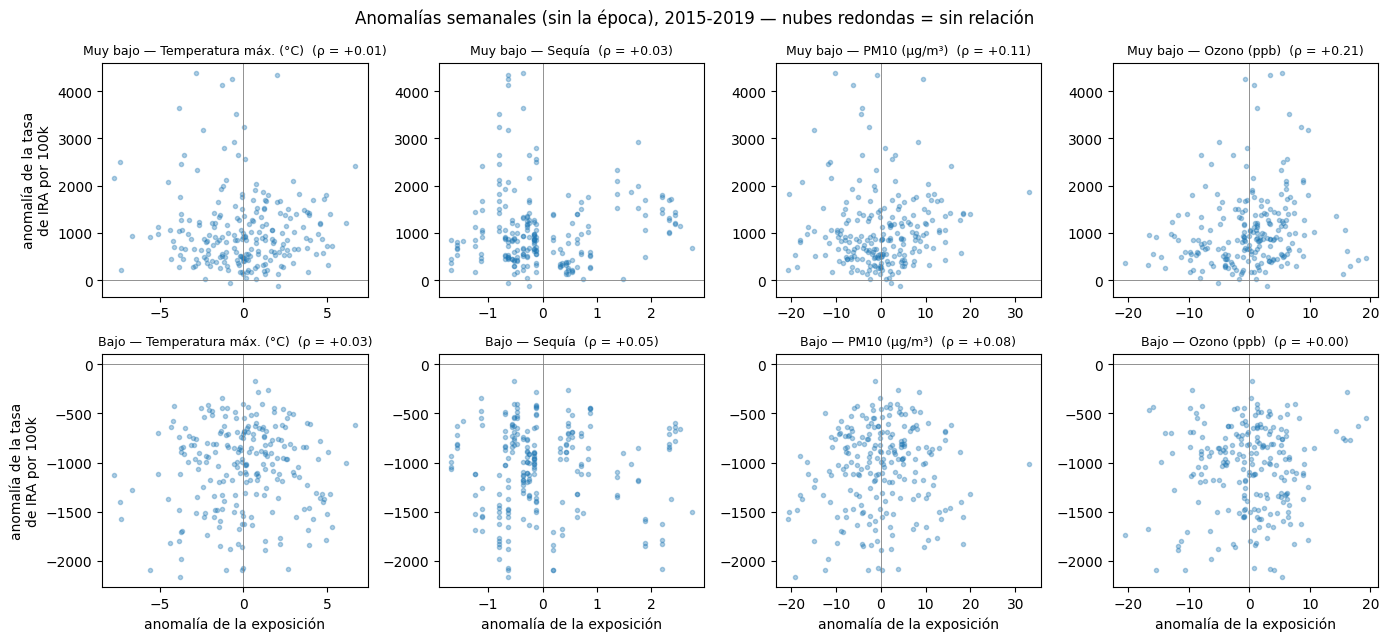

In [8]:
# ¿Reacciona distinto cada grupo a las anomalías de clima y aire?
# Se une la tasa semanal de cada grupo con las exposiciones del panel por
# fecha, se le quita la época (promedio de su mes, 2015-2019) y se correlaciona.
panel = pd.read_parquet(PROCESSED_DATA_DIR / "panel_eda_semanal.parquet")
panel = panel[~panel["anio_atipico"].astype(bool)]

expos = ["tmax_media_sem", "severidad_sequia", "pm10_ugm3", "o3_max8h_ppb"]
NOMBRE = {"tmax_media_sem": "Temperatura máx. (°C)", "severidad_sequia": "Sequía",
          "pm10_ugm3": "PM10 (µg/m³)", "o3_max8h_ppb": "Ozono (ppb)"}

tabla = semanal.merge(
    panel[["fecha_semana"] + expos], left_on="fecha", right_on="fecha_semana"
).dropna(subset=expos + ["tasa_100k"], how="any")
tabla["mes"] = tabla["fecha"].dt.month
cols = ["tasa_100k"] + expos
tabla[cols] = tabla[cols] - tabla.groupby("mes")[cols].transform("mean")

# Cada punto es UNA SEMANA: eje x = qué tan rara fue la exposición esa semana
# (vs. lo normal de su mes), eje y = qué tan rara fue la tasa de casos.
# Una nube "redonda" = no se mueven juntas; inclinada = sí hay relación.
fig, axes = plt.subplots(len(GRUPOS), len(expos), figsize=(14, 6.5))
for i, g in enumerate(GRUPOS):
    sub = tabla[tabla["grupo_margin"] == g]
    for j, e in enumerate(expos):
        ax = axes[i, j]
        ax.scatter(sub[e], sub["tasa_100k"], s=9, alpha=0.35)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.axvline(0, color="gray", linewidth=0.6)
        rho = stats.spearmanr(sub[e], sub["tasa_100k"]).statistic
        ax.set_title(f"{g} — {NOMBRE[e]}  (ρ = {rho:+.2f})", fontsize=9)
        if i == len(GRUPOS) - 1:
            ax.set_xlabel("anomalía de la exposición")
        if j == 0:
            ax.set_ylabel("anomalía de la tasa\nde IRA por 100k")
fig.suptitle("Anomalías semanales (sin la época), 2015-2019 — nubes redondas = sin relación")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "anomalias_por_marginacion.png", dpi=150, bbox_inches="tight")
plt.show()

> **Cómo leer esta gráfica:** cada punto es **una semana** (2015–2019). El
> eje horizontal dice qué tan rara fue la exposición esa semana comparada con
> lo normal de su mes (0 = una semana típica); el vertical, qué tan rara fue
> la tasa de casos del grupo. Si las semanas raras de clima vinieran acompañadas
> de tasas raras de casos, la nube se vería **inclinada**. Como las ocho son
> prácticamente **redondas** (|ρ| ≤ 0.2), ni las unidades de colonias "Muy
> bajo" ni las de "Bajo" reaccionan más que las otras a las anomalías de
> clima y aire — consistente con lo que se vio a nivel municipal: casi toda la
> señal es estacionalidad, no exposición.


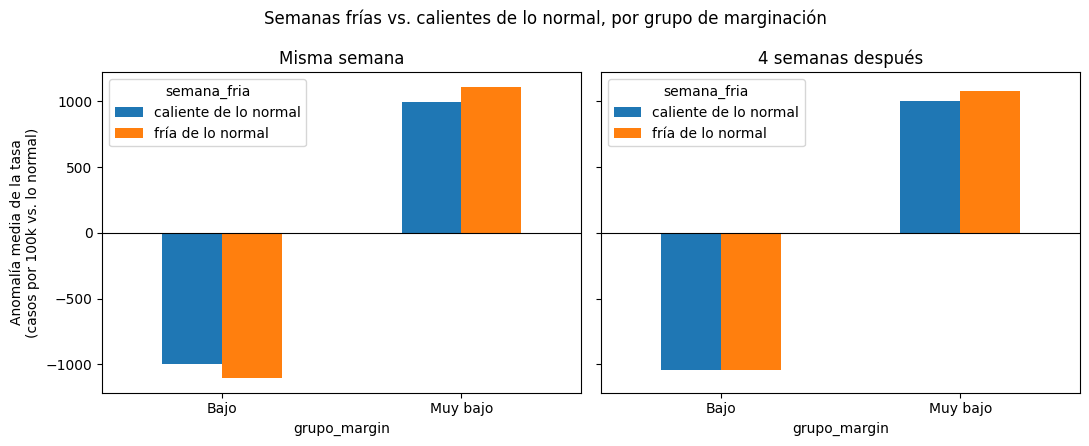

semana_fria   tras semana caliente  tras semana fría
grupo_margin                                        
Bajo                       -1043.0           -1042.0
Muy bajo                    1004.0            1080.0


In [9]:
# Otra forma de verlo: en semanas MÁS FRÍAS de lo normal (anomalía de
# temperatura < 0), ¿cuánto se desvió la tasa de cada grupo? A la izquierda
# la misma semana; a la derecha 4 semanas después (el rezago donde 3.4
# encontró la señal débil del frío).
tabla["semana_fria"] = tabla["tmax_media_sem"] < 0
tabla = tabla.sort_values(["grupo_margin", "fecha"])
tabla["tasa_100k_lag4"] = tabla.groupby("grupo_margin")["tasa_100k"].shift(-4)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col, titulo in zip(
    axes, ["tasa_100k", "tasa_100k_lag4"], ["Misma semana", "4 semanas después"]
):
    res = (
        tabla.groupby(["grupo_margin", "semana_fria"])[col].mean().unstack()
        .rename(columns={False: "caliente de lo normal", True: "fría de lo normal"})
    )
    res.plot.bar(ax=ax)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("Anomalía media de la tasa\n(casos por 100k vs. lo normal)")
fig.suptitle("Semanas frías vs. calientes de lo normal, por grupo de marginación")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "frio_vs_tasa_por_marginacion.png", dpi=150, bbox_inches="tight")
plt.show()

print(tabla.groupby(["grupo_margin", "semana_fria"])["tasa_100k_lag4"].mean()
        .unstack().rename(columns={False: "tras semana caliente", True: "tras semana fría"})
        .round(0).to_string())

> **Cómo leer esta gráfica:** en semanas **más frías de lo normal** ¿la tasa
> se desvió de lo típico? Izquierda: la misma semana. Derecha: cuatro semanas
> después — el rezago donde el análisis municipal (3.4) sí encontró una
> señal débil del frío. Si un grupo vulnerable reaccionara más, su barra
> "fría de lo normal" se alzaría más que la del otro grupo. Las barras son
> parecidas entre grupos: el frío anómalo mueve la tasa un poquito, pero por
> igual en colonias "Muy bajo" y "Bajo".


## Conclusiones

La segunda pregunta del proyecto era *"¿las zonas más marginadas de
Hermosillo son las más afectadas por las enfermedades respiratorias?"*. Con
los datos disponibles, esta libreta muestra tres cosas:

1. **No se ve un gradiente por marginación.** Las unidades en colonias más
   marginadas no atienden una carga de IRA mayor (ρ = 0.19, no significativo)
   ni responden distinto a la temporada: la amplitud invierno/verano es
   prácticamente idéntica (×3.0 vs ×2.9) y, ya sin la época, ningún grupo
   reacciona más a las anomalías de temperatura o sequía.
2. **La carga se concentra por dónde están los hospitales, no por quién
   enferma.** La colonia-sede del HIES domina la "tasa" — el recordatorio de
   que estos datos dicen *dónde se atendió* el caso, no *dónde vive* quien
   se enfermó.
3. **El hallazgo más relevante es el hueco de observación:** las 12 colonias
   más marginadas de la ciudad no tienen ninguna unidad que reporte. No se
   puede afirmar ni descartar que ahí se enferme más — **no hay datos**.

**Para el proyecto:** la pregunta de vulnerabilidad por residencia queda
abierta y necesitaría el domicilio del paciente (o notificación por colonia
de residencia). Mientras tanto, la capa de marginación por colonia ya está
integrada al proyecto — mapas, índice y población por colonia — lista para
cruzarse con esa fuente si llega a conseguirse.

## Consulta con el equipo — checkpoint

| Fecha | Participantes | Qué se mostró | Decisión |
|---|---|---|---|
| _completar_ | | Mapas por colonia + scatter marginación vs. tasa | |
